In [1]:
import pandas as pd
import numpy as np
import os

data_path = './data/'
model_path = './models/'
model_name = 'XGB_Dens_best_model.joblib'
columns_file = os.path.join(data_path, 'features_magpie.txt')

X_train = pd.read_csv(os.path.join(data_path, 'X_train.csv')).values
X_test = pd.read_csv(os.path.join(data_path, 'X_test.csv')).values       
y_train = pd.read_csv(os.path.join(data_path, 'y_train.csv')).values.ravel()
y_test = pd.read_csv(os.path.join(data_path, 'y_test.csv')).values.ravel()

R2: 0.9211
Mean Squared Error: 0.066
Mean Absolute Error: 0.1409


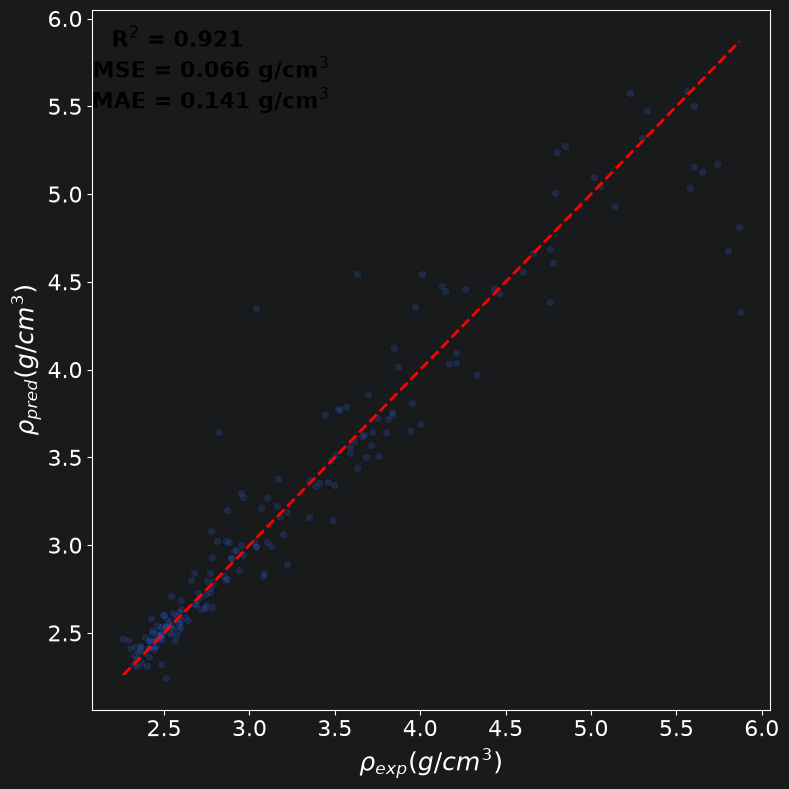

In [2]:
import joblib
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

model_filename = os.path.join(model_path, model_name)
model = joblib.load(model_filename)

y_pred=model.predict(X_test)

# Ocena modelu
R2 = round(r2_score(y_test, y_pred), 4)
print(f'R2: {R2}')
mse = round(mean_squared_error(y_test, y_pred), 4)
print(f'Mean Squared Error: {mse}')
mae = round(mean_absolute_error(y_test, y_pred), 4)
print(f'Mean Absolute Error: {mae}')

# plot the fit
plt.figure(figsize=(8, 8))
plt.scatter(y_test, y_pred, alpha=0.2, edgecolors='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel(r'$\rho _{exp} (g/cm^3)$', fontsize=18, fontweight='bold')
plt.ylabel(r'$\rho _{pred} (g/cm^3)$', fontsize=18, fontweight='bold')
plt.tick_params(axis='both', which='major', labelsize=16)

plt.text(
    0.35, 0.98,
    f'R$^2$ = {round(R2, 3)}           \nMSE = {round(mse, 3)} g/cm$^3$\nMAE = {round(mae, 3)} g/cm$^3$',
    fontsize=16,
    fontweight='bold',
    color='black',
    ha='right',
    va='top',
    transform=plt.gca().transAxes
)


plt.tight_layout()
plt.savefig('Fig4a', dpi=300)
plt.show()

In [8]:
from sklearn.inspection import permutation_importance

with open(columns_file, 'r', encoding='utf-8') as f:
    columns_names = [linia.strip() for linia in f]

result = permutation_importance(
    model, X_test, y_test, n_repeats=10, random_state=42, n_jobs=1 #-1
)
model.importance_type='weight'

importances_df = pd.DataFrame({'feature': columns_names, 'weight': model.feature_importances_, 'importance': result.importances_mean})
importances_df = importances_df.sort_values(by='weight', ascending=False)       

importances_df

,feature,weight,importance
10,MagpieData mean AtomicWeight,0.095182,0.911363
0,formers_frac,0.066833,0.008847
20,MagpieData avg_dev Electronegativity,0.051998,0.001921
36,MagpieData avg_dev NValence,0.051704,0.006690
3,modifiers_frac,0.049501,-0.002238
6,MagpieData mean MendeleevNumber,0.048619,0.001758
40,MagpieData mean GSvolume_pa,0.048325,0.011410
2,anions_frac,0.047738,0.000632
1,inters_frac,0.046416,0.001286
30,MagpieData mean NdValence,0.043772,0.010710


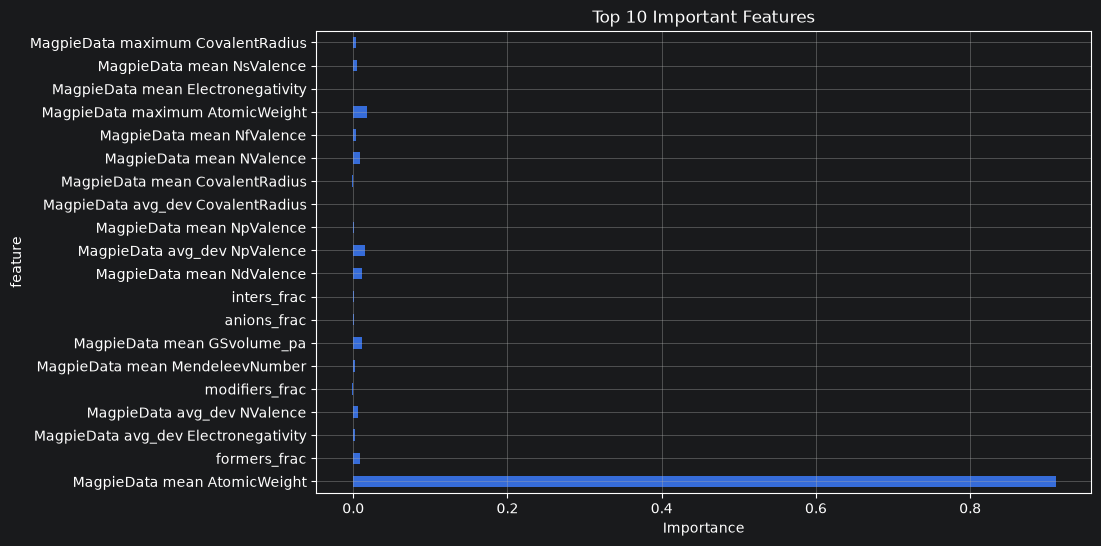

In [9]:
importances_df[:20].plot(x='feature', y='importance', kind='barh', figsize=(10, 6), legend=False)
plt.xlabel('Importance')
plt.title('Top 10 Important Features')
plt.grid()
plt.show()

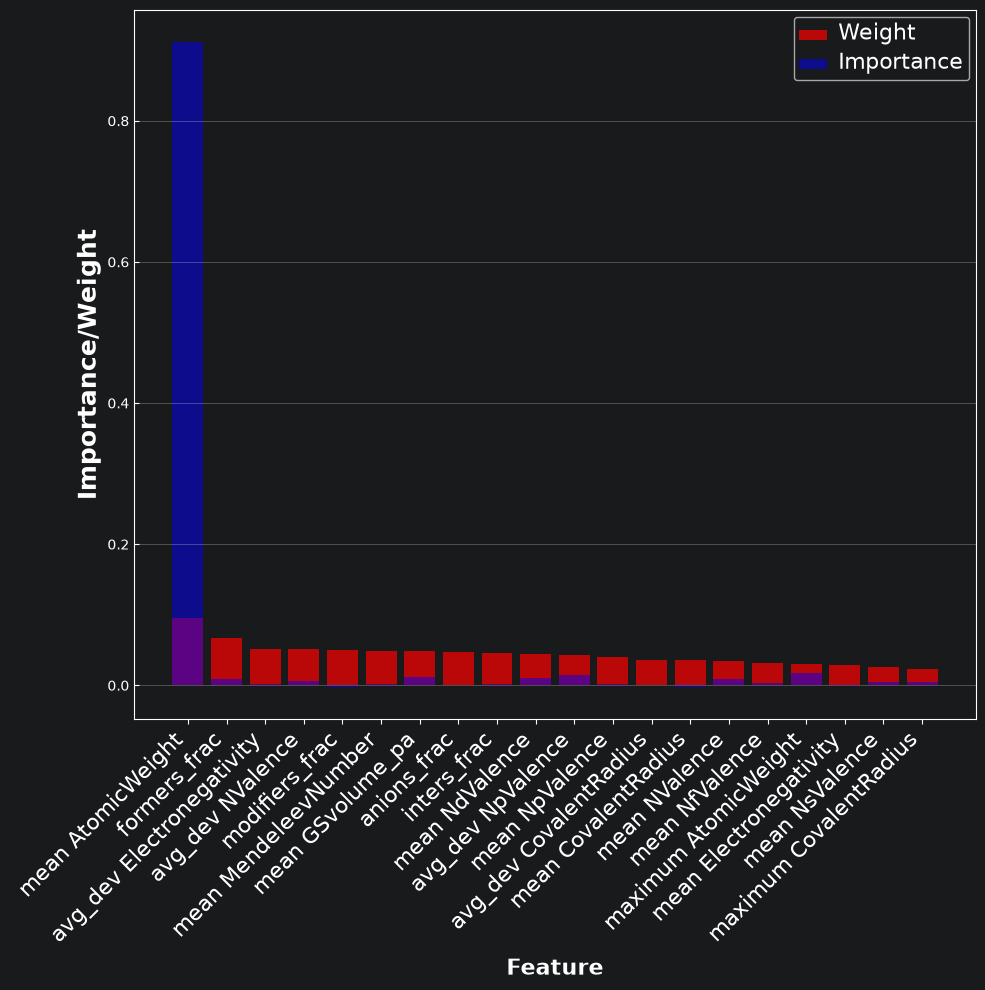

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

labels = importances_df['feature'][:20].str.replace('MagpieData', '', regex=False)
weights = importances_df['weight'][:20]
importances = importances_df['importance'][:20]

plt.bar(labels, weights, alpha=0.7, color='red', label='Weight')
plt.bar(labels, importances, alpha=0.5, color='blue', label='Importance')

legend = plt.legend()
for text in legend.get_texts():
    text.set_fontsize(16)

plt.xlabel('Feature', fontsize=16, fontweight='bold')
plt.ylabel('Importance/Weight', fontsize=18, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=16)
plt.grid(axis='y')
plt.tick_params(axis='y', direction='in')
plt.tight_layout()
plt.savefig('Fig6d', dpi=300)
plt.show()


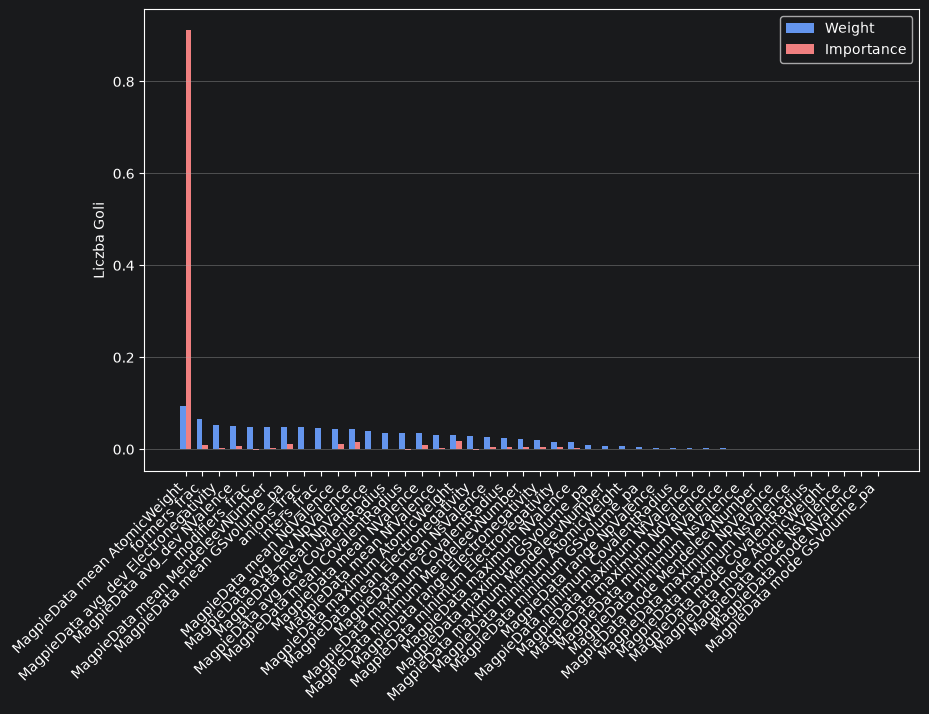

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Dane
labels = importances_df['feature']

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

# Słupki dla celów strzelonych (przesunięte w lewo)
rects1 = ax.bar(x - width/2, importances_df['weight'], width, label='Weight', color='cornflowerblue')
# Słupki dla celów straconych (przesunięte w prawo)
rects2 = ax.bar(x + width/2, importances_df['importance'], width, label='Importance', color='lightcoral')

ax.set_ylabel('Liczba Goli')
ax.set_xticks(x)
plt.xticks(rotation=45, ha='right')
ax.set_xticklabels(labels)
plt.grid(axis='y')
ax.legend()


plt.show()

In [12]:
import joblib
parametry = joblib.load('./models/MLP_Dens_best_params.joblib')

print(f"Best parameters: {parametry}")

Best parameters: {'activation': 'relu', 'batch_size': 'auto', 'hidden_layer_sizes': (128, 64, 32), 'learning_rate': 'adaptive', 'learning_rate_init': 0.0001, 'solver': 'adam'}


In [13]:
from scipy.stats import gaussian_kde

df = pd.DataFrame()
df['exp']= y_test
df['pred']= y_pred
df['diff']= df['pred'] - df['exp']
df['%_error'] = (df['diff'] / df['exp']) * 100



xy = np.vstack([df['exp'], df['%_error']]) 
kde = gaussian_kde(xy) 
df['kde'] = kde(xy) 

df


,exp,pred,diff,%_error,kde
0,4.130,4.474230,0.344230,8.334871,0.004367
1,2.471,2.488456,0.017456,0.706437,0.059498
2,2.850,2.825188,-0.024812,-0.870588,0.051164
3,2.550,2.547863,-0.002136,-0.083783,0.060690
4,3.085,2.843921,-0.241079,-7.814542,0.007340
...,...,...,...,...,...
195,2.411,2.458137,0.047137,1.955092,0.053004
196,2.596,2.535881,-0.060119,-2.315847,0.045539
197,3.950,3.807826,-0.142174,-3.599348,0.014060
198,5.020,5.099679,0.079679,1.587241,0.004911


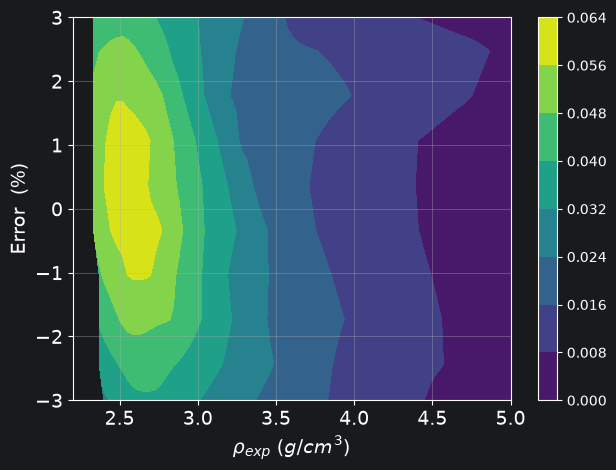

In [14]:
from scipy.interpolate import griddata

# Tworzenie siatki 
xi = np.linspace(min(df['exp']), max(df['exp']), 100) 
yi = np.linspace(min(df['%_error']), max(df['%_error']), 100) 
xi, yi = np.meshgrid(xi, yi)

# Interpolacja danych 
zi = griddata((df['exp'], df['%_error']), df['kde'], (xi, yi), method='linear') 

# Tworzenie wykresu 
plt.contourf(xi, yi, zi, cmap='viridis')
#plt.scatter(df['x'], df['delta'], alpha=0.5, c=df['z']/df['z'].max(), cmap='viridis')
plt.ylim(-3, 3)
plt.xlim(2.2, 5)
plt.colorbar() #label='Wartości z')
plt.xlabel(r'$\rho_{exp}$ ($g/cm^3$)', fontsize=14) 
plt.ylabel(r'Error  (%)', fontsize=14) 
plt.tick_params(axis='both', which='major', labelsize=14)
plt.grid(True)
plt.tight_layout()
plt.savefig('plot.png', dpi=300)

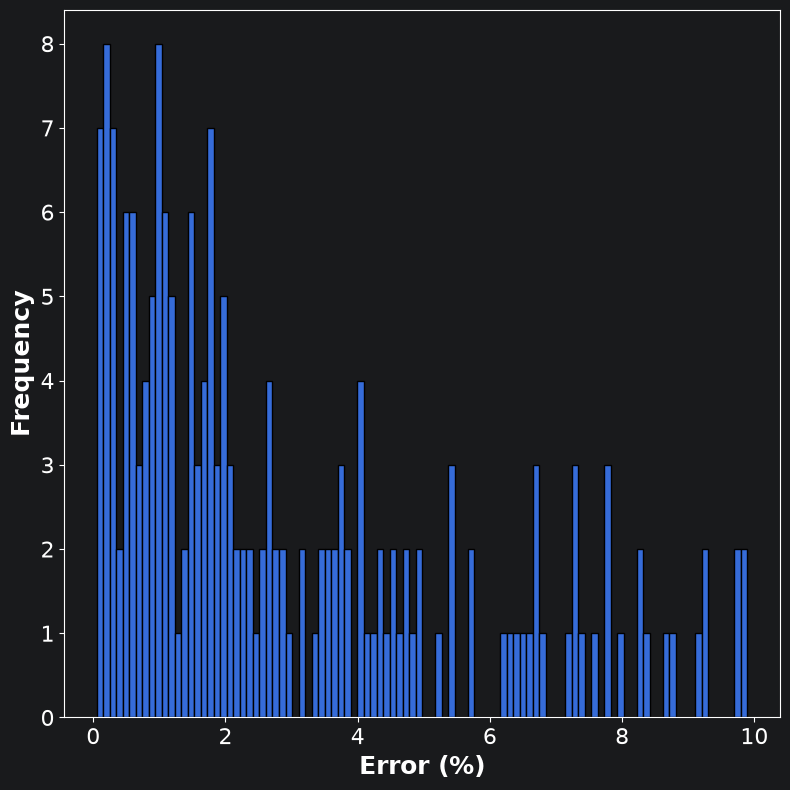

In [15]:
df_error = pd.DataFrame()

df_error['%_error'] = df['%_error'].abs()  
df_error['exp'] = df['exp']
df_error = df_error[df_error['%_error'] < 10]  # Usunięcie wartości większych niż 100%

plt.figure(figsize=(8, 8))
plt.hist(df_error['%_error'], bins=100, edgecolor='black') 
plt.xlabel(r'Error (%)', fontsize=18, fontweight='bold') 
plt.ylabel('Frequency', fontsize=18, fontweight='bold') 
plt.tick_params(axis='both', which='major', labelsize=16)
plt.tight_layout()
plt.savefig('Fig5a', dpi=300)
plt.show()

In [16]:
df['%_error'].abs().describe()

count    200.000000
mean       3.942938
std        5.224642
min        0.053397
25%        0.971188
50%        2.108096
75%        5.032320
max       43.184695
Name: %_error, dtype: float64

Współczynnik nachylenia (slope): 1.1237
Wyraz wolny (intercept): -0.6226


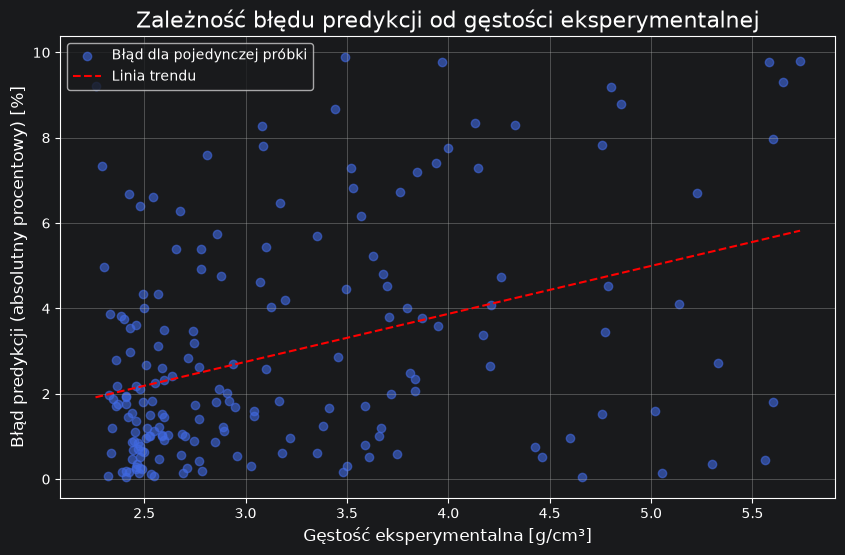

In [17]:
# Inicjalizacja figury wykresu
plt.figure(figsize=(10, 6))

# Stworzenie wykresu rozrzutu za pomocą matplotlib
plt.scatter(
    x=df_error['exp'],  # Używamy kolumny 'exp' jako osi x
    y=df_error['%_error'],  # Używamy kolumny

    alpha=0.6,          # Przezroczystość punktów
    color='royalblue',  # Kolor punktów
    label='Błąd dla pojedynczej próbki'
)

# Obliczanie i rysowanie linii trendu za pomocą numpy
# np.polyfit(x, y, 1) dopasowuje wielomian 1. stopnia (linię prostą) do danych,
# zwracając współczynnik nachylenia (slope) i wyraz wolny (intercept).
slope, intercept = np.polyfit(df_error['exp'], df_error['%_error'], 1)
print(f'Współczynnik nachylenia (slope): {slope:.4f}')
print(f'Wyraz wolny (intercept): {intercept:.4f}')


# Tworzenie punktów x i y dla linii trendu na podstawie dopasowania
# Używamy tylko minimalnej i maksymalnej wartości x, aby narysować prostą linię.
x_trend = np.array([df_error['exp'].min(), df_error['exp'].max()])
y_trend = slope * x_trend + intercept

# Rysowanie linii trendu na wykresie
plt.plot(
    x_trend,
    y_trend,
    color='red',
    linestyle='--',
    label='Linia trendu'
)

# Tytuły, etykiety i inne elementy estetyczne
plt.title('Zależność błędu predykcji od gęstości eksperymentalnej', fontsize=16)
plt.xlabel('Gęstość eksperymentalna [g/cm³]', fontsize=12)
plt.ylabel('Błąd predykcji (absolutny procentowy) [%]', fontsize=12)
plt.grid(True)
plt.legend() # Wyświetlenie legendy
plt.show()


C:\Users\maxim\PycharmProjects\MLM\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Background dataset has 800 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=800 when initializing the masker.


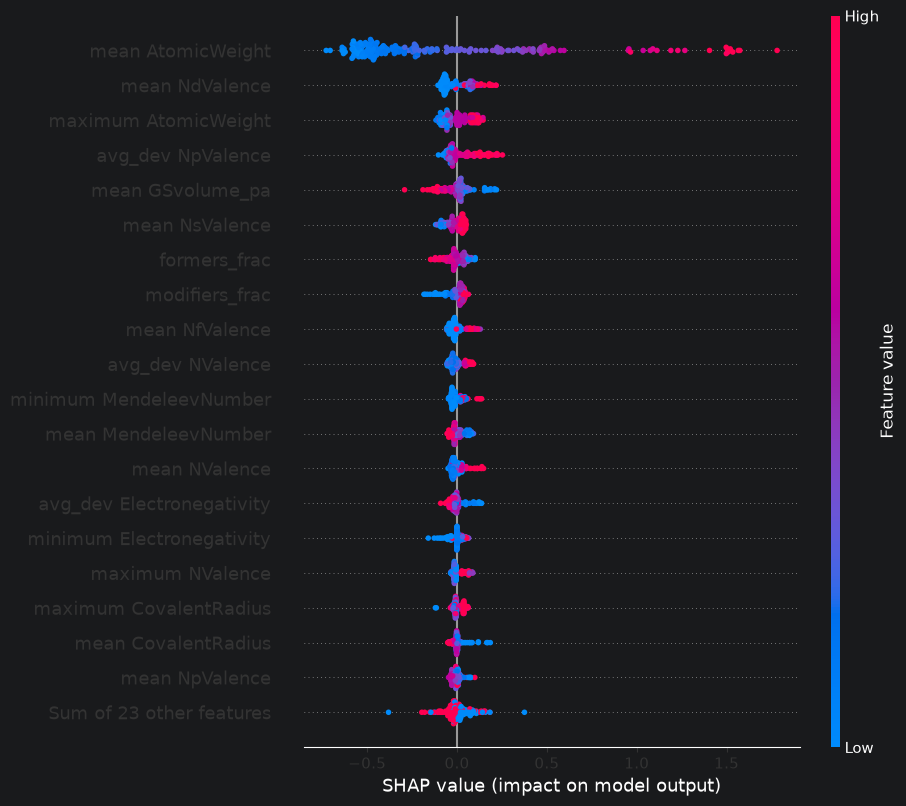

<Figure size 640x480 with 0 Axes>

In [18]:
import shap

columns_names = [s.replace('MagpieData ', '') for s in columns_names]

# Oblicz wartości SHAP dla modelu (np. XGBoost, RandomForest, SVR, MLP)
explainer = shap.Explainer(model, X_train, feature_names=columns_names)
shap_values = explainer(X_test)

# Beeswarm plot (wykres podsumowujący ważność cech)
plt.figure(figsize=(12, 8))
shap.plots.beeswarm(shap_values, max_display=20)
plt.savefig('Fig7.png', dpi=300)
plt.show()

In [21]:
import matplotlib.pyplot as plt
import shap

shap.plots.beeswarm(shap_values, max_display=20, show=False) # matplotlib=True
plt.savefig('Fig7.png', dpi=300)
plt.close()

Redukcja wymiarowości za pomocą t-SNE zakończona.
Generowanie wizualizacji przestrzeni cech...


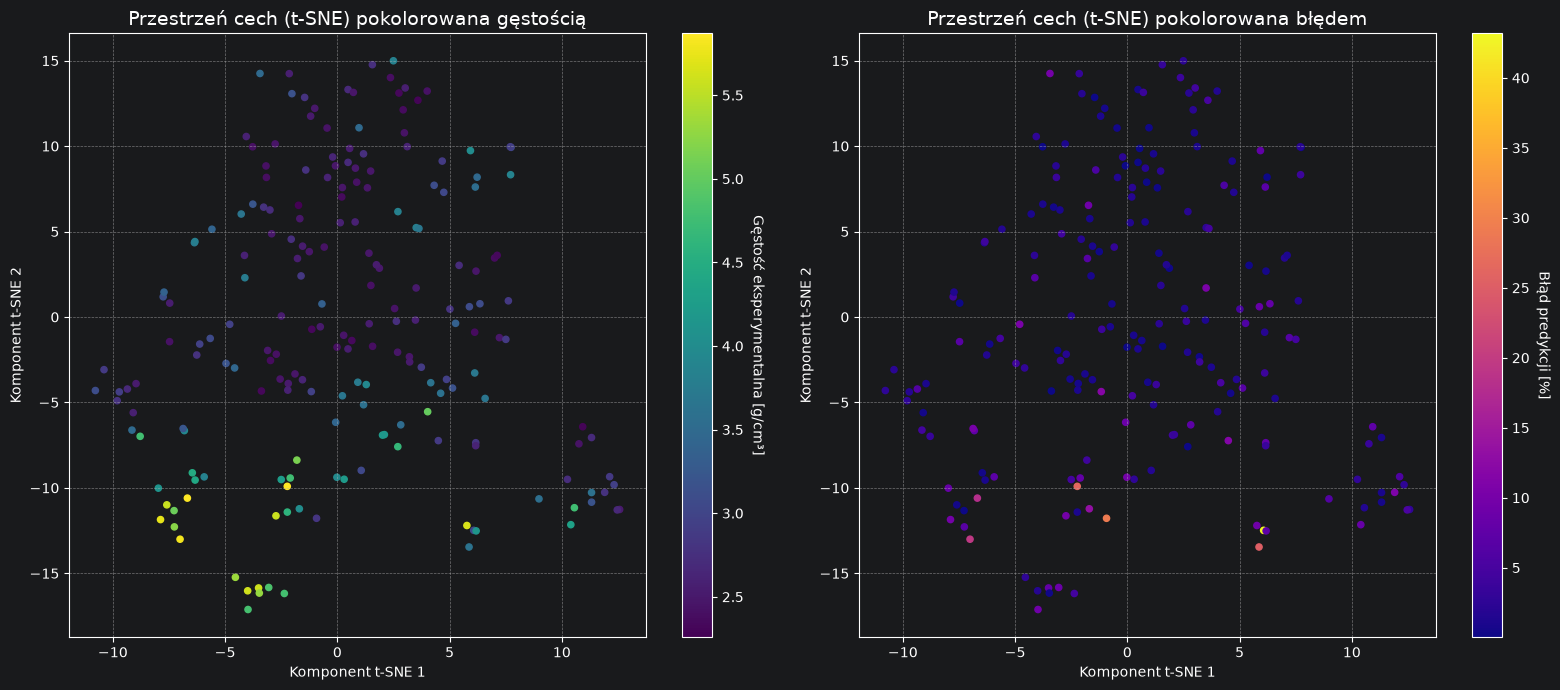

In [22]:
from sklearn.manifold import TSNE

absolute_percentage_error=df['%_error'].abs().values  # Używamy wartości bezwzględnych błędu procentowego

# --------------------------------------------------------------------------
# KROK 2: Redukcja wymiarowości za pomocą t-SNE
# --------------------------------------------------------------------------

# Inicjalizacja obiektu TSNE.
# n_components=2: redukujemy do dwóch wymiarów.
# perplexity: kluczowy parametr, związany z liczbą najbliższych sąsiadów. Typowe wartości to 5-50.
# n_iter: liczba iteracji optymalizacji.
tsne_reducer = TSNE(n_components=2, perplexity=30, random_state=42)

# Dopasowanie i transformacja danych testowych do przestrzeni 2D
embedding = tsne_reducer.fit_transform(X_test)

print("Redukcja wymiarowości za pomocą t-SNE zakończona.")


# --------------------------------------------------------------------------
# KROK 3: Generowanie wykresów (logika bez zmian, tylko etykiety)
# --------------------------------------------------------------------------

print("Generowanie wizualizacji przestrzeni cech...")

# Tworzenie figury z dwoma podwykresami obok siebie
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# --- Wykres 1: Pokolorowany według gęstości eksperymentalnej ---
scatter1 = axes[0].scatter(
    embedding[:, 0], embedding[:, 1], c=y_test, cmap='viridis', s=20
)
cbar1 = fig.colorbar(scatter1, ax=axes[0])
cbar1.set_label('Gęstość eksperymentalna [g/cm³]', rotation=270, labelpad=15)
axes[0].set_title('Przestrzeń cech (t-SNE) pokolorowana gęstością', fontsize=14)

# --- Wykres 2: Pokolorowany według błędu predykcji ---
scatter2 = axes[1].scatter(
    embedding[:, 0], embedding[:, 1], c=absolute_percentage_error, cmap='plasma', s=20
)
cbar2 = fig.colorbar(scatter2, ax=axes[1])
cbar2.set_label('Błąd predykcji [%]', rotation=270, labelpad=15)
axes[1].set_title('Przestrzeń cech (t-SNE) pokolorowana błędem', fontsize=14)

# Ustawienie wspólnych etykiet dla obu wykresów
for ax in axes:
    ax.set_xlabel('Komponent t-SNE 1') # Zmiana etykiety
    ax.set_ylabel('Komponent t-SNE 2') # Zmiana etykiety
    ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


In [23]:
columns_names = [s.replace('MagpieData ', '') for s in columns_names]
columns_names

['formers_frac',
 'inters_frac',
 'anions_frac',
 'modifiers_frac',
 'minimum MendeleevNumber',
 'maximum MendeleevNumber',
 'mean MendeleevNumber',
 'mode MendeleevNumber',
 'minimum AtomicWeight',
 'maximum AtomicWeight',
 'mean AtomicWeight',
 'mode AtomicWeight',
 'minimum CovalentRadius',
 'maximum CovalentRadius',
 'mean CovalentRadius',
 'avg_dev CovalentRadius',
 'mode CovalentRadius',
 'minimum Electronegativity',
 'range Electronegativity',
 'mean Electronegativity',
 'avg_dev Electronegativity',
 'minimum NsValence',
 'maximum NsValence',
 'mean NsValence',
 'mode NsValence',
 'maximum NpValence',
 'range NpValence',
 'mean NpValence',
 'avg_dev NpValence',
 'maximum NdValence',
 'mean NdValence',
 'maximum NfValence',
 'mean NfValence',
 'minimum NValence',
 'maximum NValence',
 'mean NValence',
 'avg_dev NValence',
 'mode NValence',
 'minimum GSvolume_pa',
 'maximum GSvolume_pa',
 'mean GSvolume_pa',
 'mode GSvolume_pa']

In [24]:
import matplotlib
print(matplotlib.__version__)

3.11.2
